# G10: continue CNN v3 past epoch 60 (AdamW, GPU 0)
CNN v3 stopped at its 60-epoch limit while still improving slowly (best epoch 57, mean trash-head val AUC 0.874).
This notebook **continues that run** instead of restarting: it loads `Models/cnn_adamw_v3_best.keras`, keeps the last learning rate
and the frozen satellite head, and trains up to 40 more epochs with the same data, losses, LR halving and early stopping.

- Saves as a **new run**, `cnn_adamw_v3_long`, so the v3 results stay untouched.
- A checkpoint is written **only if it beats v3's best (0.874)**. If nothing is saved, v3 stays the final CNN.
- About 10 minutes per epoch; early stopping usually ends it sooner than 40 epochs.

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"        # this notebook's GPU

EXPERIMENT = "cnn_adamw_v3_long"                  # name used for the saved model, log and history
OPTIMIZER  = "adamw"
OUT_DIR    = r"C:\Users\Raphaelo\Documents\Datasets\runs"
WORKERS    = 8                           # image-loading threads
SOURCE_RUN   = "cnn_adamw_v3"    # the run to continue (Models/<SOURCE_RUN>_best.keras + its history)
EXTRA_EPOCHS = 60                # at most this many more epochs


## 1. Imports

In [2]:
import os, csv, json, math, time, random, collections
import numpy as np
import cv2
import torch
import keras
from keras import layers
import matplotlib.pyplot as plt

cv2.setNumThreads(1)   # one thread per loader worker; the workers already run in parallel
keras.mixed_precision.set_global_policy("mixed_float16")   # 16-bit maths, 32-bit outputs and loss
torch.backends.cudnn.benchmark = True                      # let cuDNN pick the fastest conv algorithms
print("Keras", keras.__version__, "| backend", keras.backend.backend(), "| PyTorch", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0))

Keras 3.15.1 | backend torch | PyTorch 2.12.0.dev20260408+cu128
GPU: NVIDIA GeForce RTX 5060 Ti


## 2. Configuration
Paths, 320 input, head of each dataset, batch mix (square-root balanced on the v3 pools: **26 / 26 / 23 / 21**), clean share (20% for SeaClear, BePLi, UCWD), augmentation recipes, **head sizes per dataset** and the satellite lever's patience.

In [3]:
PREPARED   = r"C:\Users\Raphaelo\Documents\Datasets\prepared"
INPUT      = 320
SOURCES    = ["seaclear", "bepli", "ucwd", "mados"]
HEAD_OF    = {"seaclear": "underwater", "bepli": "shore", "ucwd": "drone", "mados": "satellite"}
HEADS      = ["underwater", "shore", "drone", "satellite"]
VIEW_IDX   = {"seaclear": 0, "bepli": 1, "ucwd": 2, "mados": 3}

CLEAN_SHARE   = 0.20                                    # clean share of the training pool (SeaClear, UCWD)
SAMPLE_CLEAN  = {"seaclear": True, "bepli": True, "ucwd": True, "mados": False}   # BePLi 3x3 tiles are 34% clean -> sampled to 20% too
MIX_96        = {"seaclear": 26, "bepli": 26, "ucwd": 23, "mados": 21}   # square-root balanced on the v3 pools
MIX_32        = {"seaclear": 8,  "bepli": 9,  "ucwd": 8,  "mados": 7}    # (SeaClear 16.3k, BePLi 16.6k, UCWD 13.7k, MADOS 11.5k)
STEPS_PER_EPOCH = 450

# live augmentation per dataset
AUG = {
    "seaclear": dict(rot90=False, hflip=True, vflip=False, tilt=15, bright=0.25, contrast=0.25),
    "bepli":    dict(rot90=False, hflip=True, vflip=False, tilt=15, bright=0.15, contrast=0.15),
    "ucwd":     dict(rot90=True,  hflip=True, vflip=True,  tilt=15, bright=0.15, contrast=0.15),
    "mados":    dict(rot90=False, hflip=False, vflip=False, tilt=15, bright=0.10, contrast=0.10),  # 8 orientations saved
}
CROP_SCALE = (0.90, 1.00)    # random zoom: keep 90-100% of the tile side

# head sizes per dataset (hidden layers, AlphaDropout rate), recomputed for the v3 labels.
# Rule: first layer = 512 x sqrt(label instances / shore's label instances), rounded to a multiple of 64,
#       at least 128; each next layer is half the previous; 3 layers for 13+ classes, 2 for 7 classes.
#       Applied only to heads whose data changed in v3 (underwater); the others keep their v2 size.
#       (shore has the most labels in training, 28,123, so it anchors at 512)
# Training label instances (one per class per tile): shore 28,123 | underwater 15,575 (was 11,144 before
# the v3 relabel) | drone 12,500 | satellite 1,053 unique patches.
HEAD_CFG = {
    "viewpoint":  ((128,),          0.1),   # easy task (~99.6%), small head (not part of the rule)
    "underwater": ((384, 192, 96),  0.2),   # 512*sqrt(15575/28123) = 381 -> 384; keeps 0.2 dropout (v2 train 0.89 vs val 0.84)
    "shore":      ((512, 256, 128), 0.1),   # anchor (most labels); v2 still did not overfit (train 0.80 vs val 0.81)
    "drone":      ((256, 128),      0.1),   # kept as in v2: drone data did not change and it fitted well (rule would give 320)
    "satellite":  ((128, 64),       0.2),   # 512*sqrt(1053/28123) = 99 -> minimum 128; overfits (train 0.94 vs val 0.85)
}
# "trash present?" neuron per trash head (v3): 1 sigmoid output = P(tile has trash); P(no trash) = 1 - it.
# Satellite: most MADOS classes are not trash (ships, platforms, algae, waves) -> pollution = debris or oil.
TRASH_CLASSES = {"underwater": None, "shore": None, "drone": None,          # None = any of the head's classes
                 "satellite": ["Marine Debris", "Oil Spill"]}
TRASH_LOSS_WEIGHT = 0.5

SATELLITE_FREEZE_PATIENCE = 8   # longest gap between satellite val-AUC improvements in the v1 logs was 7 epochs

## 3. Data: manifests and images

In [4]:
def load_classes(prepared=PREPARED):
    return json.load(open(os.path.join(prepared, "classes.json"), encoding="utf-8"))

def load_manifest(split, prepared=PREPARED):
    with open(os.path.join(prepared, "manifests", f"{split}.csv"), encoding="utf-8") as f:
        rows = list(csv.DictReader(f))
    for r in rows:
        r["clean"] = int(r["clean"])
        r["labels"] = [c for c in r["labels"].split(";") if c]
    return rows

## 4. Augmentation
Training only, fresh random roll each time: zoom/crop (90–100%), orientation (only where realistic), small tilt with mirrored corners, brightness/contrast.

In [5]:
def read_image(path):
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(path)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def augment(img, src, rng):
    a = AUG[src]
    h, w = img.shape[:2]
    # random zoom / crop
    s = rng.uniform(*CROP_SCALE)
    ch, cw = max(1, int(h * s)), max(1, int(w * s))
    y0, x0 = rng.randint(0, h - ch), rng.randint(0, w - cw)
    img = img[y0:y0 + ch, x0:x0 + cw]
    img = cv2.resize(img, (INPUT, INPUT), interpolation=cv2.INTER_AREA if ch > INPUT else cv2.INTER_LINEAR)
    # orientation
    if a["rot90"]:
        img = np.rot90(img, rng.randint(0, 3))
    if a["hflip"] and rng.random() < 0.5:
        img = img[:, ::-1]
    if a["vflip"] and rng.random() < 0.5:
        img = img[::-1]
    img = np.ascontiguousarray(img)
    # small tilt with mirrored corners (no black triangles)
    if a["tilt"]:
        ang = rng.uniform(-a["tilt"], a["tilt"])
        M = cv2.getRotationMatrix2D((INPUT / 2, INPUT / 2), ang, 1.0)
        img = cv2.warpAffine(img, M, (INPUT, INPUT), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)
    # brightness / contrast
    img = img.astype(np.float32)
    b = 1.0 + rng.uniform(-a["bright"], a["bright"])
    c = 1.0 + rng.uniform(-a["contrast"], a["contrast"])
    mean = img.mean()
    img = np.clip((img - mean) * c + mean * b, 0, 255)
    return img

def plain(img):
    h, w = img.shape[:2]
    img = cv2.resize(img, (INPUT, INPUT), interpolation=cv2.INTER_AREA if h > INPUT else cv2.INTER_LINEAR)
    return img.astype(np.float32)

## 5. Labels and loss mask
Sample weight per head: 1 for the viewpoint head and the image's own trash head, 0 for the others. A **frozen** head gets 0 everywhere.

In [6]:
def make_targets(rows, classes, frozen=()):
    """-> y dict (one entry per head) and sample_weight dict (the loss mask).
    Heads listed in `frozen` get weight 0 everywhere (they no longer learn)."""
    n = len(rows)
    y = {"viewpoint": np.zeros((n, 4), np.float32)}
    sw = {"viewpoint": np.ones((n,), np.float32)}
    idx = {h: {c: i for i, c in enumerate(classes[h])} for h in HEADS}
    for h in HEADS:
        y[h] = np.zeros((n, len(classes[h])), np.float32)
        sw[h] = np.zeros((n,), np.float32)
        y[h + "_trash"] = np.zeros((n, 1), np.float32)          # the head's "trash present?" neuron
    for i, r in enumerate(rows):
        src = r["source"]; h = HEAD_OF[src]
        y["viewpoint"][i, VIEW_IDX[src]] = 1.0
        sw[h][i] = 0.0 if h in frozen else 1.0   # only this image's own head learns from it
        for c in r["labels"]:
            y[h][i, idx[h][c]] = 1.0
        trash = TRASH_CLASSES[h]
        y[h + "_trash"][i, 0] = float(any(trash is None or c in trash for c in r["labels"]))
    for h in HEADS:
        sw[h + "_trash"] = sw[h]                                  # same mask (and same freeze) as its head
    return y, sw

## 6. Balanced training batches
One shuffled deck per dataset; each batch deals a fixed number from each. Clean tiles re-sampled at every reshuffle.

In [7]:
class BalancedTrainSet(keras.utils.PyDataset):
    """Each batch = fixed number of tiles from each dataset (the mix). Each dataset is its own
    shuffled deck that reshuffles when it runs out; clean tiles are re-sampled at every reshuffle."""

    def __init__(self, rows, classes, mix, steps=STEPS_PER_EPOCH, seed=0, workers=8, prepared=PREPARED, **kw):
        super().__init__(workers=workers, use_multiprocessing=False, max_queue_size=16, **kw)
        self.prepared = prepared
        self.classes, self.mix, self.steps = classes, mix, steps
        self.rng = random.Random(seed)
        self.by_src = {s: [r for r in rows if r["source"] == s] for s in SOURCES}
        self.deck = {s: [] for s in SOURCES}
        self.pos = {s: 0 for s in SOURCES}
        self.epoch = 0
        self.frozen_heads = set()   # filled by FreezeHeadOnPlateau
        self._schedule()

    def _new_deck(self, s):
        rows = self.by_src[s]
        if SAMPLE_CLEAN[s]:
            trash = [r for r in rows if not r["clean"]]
            clean = [r for r in rows if r["clean"]]
            k = min(len(clean), round(len(trash) * CLEAN_SHARE / (1 - CLEAN_SHARE)))
            deck = trash + self.rng.sample(clean, k)
        else:
            deck = list(rows)
        self.rng.shuffle(deck)
        return deck

    def _draw(self, s, n):
        out = []
        while len(out) < n:
            if self.pos[s] >= len(self.deck[s]):
                self.deck[s], self.pos[s] = self._new_deck(s), 0
            take = min(n - len(out), len(self.deck[s]) - self.pos[s])
            out += self.deck[s][self.pos[s]:self.pos[s] + take]; self.pos[s] += take
        return out

    def _schedule(self):
        self.batches = [[r for s in SOURCES for r in self._draw(s, self.mix[s])] for _ in range(self.steps)]
        self.seeds = [self.rng.randrange(2**31) for _ in range(self.steps)]

    def __len__(self):
        return self.steps

    def __getitem__(self, i):
        rows = self.batches[i]
        rng = random.Random(self.seeds[i] + 7919 * self.epoch)
        x = np.stack([augment(read_image(os.path.join(self.prepared, "images", r["path"])), r["source"], rng)
                      for r in rows])
        y, sw = make_targets(rows, self.classes, self.frozen_heads)
        return x, y, sw

    def on_epoch_end(self):
        self.epoch += 1
        self._schedule()

## 7. Validation / test set
Every tile once, in order, no augmentation.

In [8]:
class EvalSet(keras.utils.PyDataset):
    """Validation / test: every tile once, in order, no augmentation."""

    def __init__(self, rows, classes, batch=128, workers=8, prepared=PREPARED, **kw):
        super().__init__(workers=workers, use_multiprocessing=False, max_queue_size=16, **kw)
        self.prepared = prepared
        self.rows, self.classes, self.batch = rows, classes, batch

    def __len__(self):
        return math.ceil(len(self.rows) / self.batch)

    def __getitem__(self, i):
        rows = self.rows[i * self.batch:(i + 1) * self.batch]
        x = np.stack([plain(read_image(os.path.join(self.prepared, "images", r["path"]))) for r in rows])
        y, sw = make_targets(rows, self.classes)
        return x, y, sw

## 8. Model
Input 320×320 → −1…+1 → 4 × [Conv → BatchNorm → LeakyReLU → MaxPool] (32/64/128/256) → GAP + GMP → BatchNorm → 5 heads (Dense + SELU + AlphaDropout).

**Head sizes per dataset** (recomputed for the v3 labels). Rule: first layer = 512 × √(training label instances ÷ shore's), rounded to a multiple of 64 (minimum 128); each next layer is half; 3 layers for 13+ classes, 2 for 7. Applied to the head whose data changed in v3 (underwater); the others keep their v2 sizes.

| Head | Training labels | Hidden layers | Dropout | Note |
|:--|--:|:--|:-:|:--|
| shore | 28,123 | 512 → 256 → 128 | 0.1 | anchor (most labels); did not overfit in v2 |
| underwater | **15,575** (was 11,144) | **384 → 192 → 96** (was 256-128-64) | 0.2 | more labels after the v3 relabel; mild overfit in v2 |
| drone | 12,500 | 256 → 128 | 0.1 | unchanged: data unchanged, fitted well |
| satellite | 1,053 patches | 128 → 64 | 0.2 | minimum size; overfits |
| viewpoint | | 128 | 0.1 | easy task (not part of the rule) |

**Trash-present neuron (v3):** each trash head has one extra sigmoid output next to its class outputs, `<head>_trash` = P(the tile has trash) (P(no trash) = 1 − it, so one neuron carries both answers). Trash = any of the head's classes; satellite = Marine Debris or Oil Spill. Binary cross-entropy, loss weight 0.5, same mask and same satellite freeze as its head. It is reported (`val_<head>_trash_auc`) but not monitored, so checkpoints still follow the 4 class heads.

In [9]:
def head(x, name, units, n_out, activation, dropout, trash_neuron=False):
    for u in units:
        x = layers.Dense(u, activation="selu", kernel_initializer="lecun_normal", name=f"{name}_dense{u}")(x)
        x = layers.AlphaDropout(dropout, name=f"{name}_adrop{u}")(x)
    out = {name: layers.Dense(n_out, activation=activation, dtype="float32", name=name)(x)}
    if trash_neuron:   # sits next to the class outputs, on the same last hidden layer
        out[name + "_trash"] = layers.Dense(1, activation="sigmoid", dtype="float32", name=name + "_trash")(x)
    return out

def make_heads(x, classes):
    """The 5 heads, sized per dataset (HEAD_CFG). Each trash head also gets a 'trash present?' neuron."""
    n_out = {"viewpoint": 4, **{h: len(classes[h]) for h in HEADS}}
    outs = {}
    for name, (units, drop) in HEAD_CFG.items():
        outs.update(head(x, name, units, n_out[name], "softmax" if name == "viewpoint" else "sigmoid", drop,
                         trash_neuron=name in HEADS))
    return outs

def build_cnn(classes, filters=(32, 64, 128, 256), leaky=0.1):
    inp = keras.Input((INPUT, INPUT, 3), name="image")
    x = layers.Rescaling(1 / 127.5, offset=-1.0, name="scale_to_pm1")(inp)      # 0..255 -> -1..+1
    for i, f in enumerate(filters, 1):
        x = layers.Conv2D(f, 3, padding="same", use_bias=False, name=f"block{i}_conv")(x)
        x = layers.BatchNormalization(name=f"block{i}_bn")(x)
        x = layers.LeakyReLU(negative_slope=leaky, name=f"block{i}_lrelu")(x)
        x = layers.MaxPooling2D(name=f"block{i}_pool")(x)
    x = layers.Concatenate(name="gap_gmp")([layers.GlobalAveragePooling2D(name="gap")(x),
                                             layers.GlobalMaxPooling2D(name="gmp")(x)])
    x = layers.BatchNormalization(name="pooled_bn")(x)
    out = make_heads(x, classes)
    return keras.Model(inp, out, name="g10_cnn")

## 9. Loss, optimizer, monitoring, satellite lever, training loop
Binary focal loss (γ = 2) for the trash heads, categorical cross-entropy for viewpoint (weight 0.5).

- **Monitoring:** checkpoints, learning-rate halving and early stopping follow `val_trash_auc` (mean validation AUC of the four trash heads), not the total loss, which the viewpoint head dominates.
- **Satellite lever:** when the satellite head's validation AUC has not improved for **8 epochs** (the longest gap between improvements in the two v1 logs was 7), its best weights are restored and it stops learning (loss mask 0, weights pinned). The other heads keep training. In v2 it fired at epoch 37 and stopped the satellite head from overfitting further (train 0.94 vs val 0.85).

Phase 1: batch 32 (8/9/8/7) for 3 epochs; phase 2: batch 96 (26/26/23/21), reduce-on-plateau (patience 4), early stopping (patience 8).

In [10]:
class TrashAUC(keras.callbacks.Callback):
    """Adds val_trash_auc = mean validation AUC of the 4 trash heads to the epoch logs.
    Checkpoints, learning-rate halving and early stopping follow THIS number, not the total
    loss (which is dominated by the viewpoint head). Must be the first callback in the list."""
    def on_epoch_end(self, epoch, logs=None):
        if logs is not None and all(f"val_{h}_auc" in logs for h in HEADS):
            logs["val_trash_auc"] = float(np.mean([logs[f"val_{h}_auc"] for h in HEADS]))
            print(f" - val_trash_auc: {logs['val_trash_auc']:.4f}")

MONITOR = dict(monitor="val_trash_auc", mode="max")


class FreezeHeadOnPlateau(keras.callbacks.Callback):
    """The satellite lever. When the head's validation AUC has not improved for `patience` epochs,
    its best weights are put back and it stops learning: its loss mask becomes 0 (no gradient, so it
    also stops pulling on the shared backbone), and its weights are pinned to that best version after
    every batch (this also cancels any leftover optimizer momentum). The other heads keep training.
    (Layers are not switched to trainable=False mid-training: the optimizer was built for a fixed
    set of variables, and changing that set during fit() breaks it.)"""
    def __init__(self, head_name, train_sets, patience=SATELLITE_FREEZE_PATIENCE):
        super().__init__()
        self.head_name, self.train_sets, self.patience = head_name, train_sets, patience
        self.best, self.wait, self.frozen, self.best_weights = -1.0, 0, False, None
        self.frozen_at = None

    def _layers(self):
        return [l for l in self.model.layers
                if (l.name == self.head_name or l.name.startswith(self.head_name + "_")) and l.weights]

    def _pin(self):
        for l, w in zip(self._layers(), self.best_weights):
            l.set_weights(w)

    def on_train_batch_end(self, batch, logs=None):
        if self.frozen:
            self._pin()

    def on_epoch_end(self, epoch, logs=None):
        auc = (logs or {}).get(f"val_{self.head_name}_auc")
        if self.frozen or auc is None:
            return
        if auc > self.best:
            self.best, self.wait = auc, 0
            self.best_weights = [l.get_weights() for l in self._layers()]
            return
        self.wait += 1
        if self.wait >= self.patience:
            self._pin()
            for ds in self.train_sets:
                ds.frozen_heads.add(self.head_name)
            self.frozen, self.frozen_at = True, epoch + 1
            print(f"\n[lever] '{self.head_name}' head frozen after epoch {epoch + 1} "
                  f"(no val AUC gain for {self.patience} epochs; best weights restored, AUC {self.best:.4f})")


LOSS_WEIGHTS = {"viewpoint": 0.5, "underwater": 1.0, "shore": 1.0, "drone": 1.0, "satellite": 1.0}

def make_optimizer(name, lr=1e-3, weight_decay=1e-4):
    if name == "adam":
        return keras.optimizers.Adam(learning_rate=lr)
    if name == "adamw":
        opt = keras.optimizers.AdamW(learning_rate=lr, weight_decay=weight_decay)
        opt.exclude_from_weight_decay(var_names=["bias", "gamma", "beta"])   # no decay on biases / BatchNorm
        return opt
    raise ValueError(name)

def compile_model(model, classes, optimizer):
    focal = lambda: keras.losses.BinaryFocalCrossentropy(gamma=2.0, apply_class_balancing=True, alpha=0.25)
    model.compile(
        optimizer=optimizer,
        loss={"viewpoint": keras.losses.CategoricalCrossentropy(),
              **{h: focal() for h in HEADS},
              **{h + "_trash": keras.losses.BinaryCrossentropy() for h in HEADS}},   # trash/no trash: classes ~balanced
        loss_weights={**LOSS_WEIGHTS, **{h + "_trash": TRASH_LOSS_WEIGHT for h in HEADS}},
        weighted_metrics={"viewpoint": [keras.metrics.CategoricalAccuracy(name="acc")],
                          **{h: [keras.metrics.AUC(multi_label=True, num_labels=len(classes[h]), name="auc")]
                             for h in HEADS},
                          **{h + "_trash": [keras.metrics.AUC(name="auc")] for h in HEADS}},
    )
    return model


def run_training(name, optimizer_name, out_dir, max_epochs=60, warmup_epochs=3, lr=1e-3, seed=42,
                 workers=8, prepared=PREPARED, steps=STEPS_PER_EPOCH):
    """Full training run: batch 32 for the warm-up epochs, then 96. Returns (model, history dict)."""
    try:
        import torch
        torch.backends.cudnn.benchmark = True    # let cuDNN pick the fastest conv algorithms once
    except ImportError:
        pass
    keras.utils.set_random_seed(seed)
    keras.mixed_precision.set_global_policy("mixed_float16")   # 16-bit maths, 32-bit outputs/loss
    os.makedirs(out_dir, exist_ok=True)
    classes = load_classes(prepared)
    train_rows, val_rows = load_manifest("train", prepared), load_manifest("val", prepared)
    val = EvalSet(val_rows, classes, workers=workers, prepared=prepared)

    model = build_cnn(classes)
    compile_model(model, classes, make_optimizer(optimizer_name, lr))
    ckpt = os.path.join(out_dir, f"{name}_best.keras")
    train32 = BalancedTrainSet(train_rows, classes, MIX_32, steps=steps, seed=seed, workers=workers, prepared=prepared)
    train96 = BalancedTrainSet(train_rows, classes, MIX_96, steps=steps, seed=seed + 1, workers=workers, prepared=prepared)
    common = [TrashAUC(),
              FreezeHeadOnPlateau("satellite", [train32, train96]),
              keras.callbacks.CSVLogger(os.path.join(out_dir, f"{name}_log.csv"), append=True),
              keras.callbacks.ModelCheckpoint(ckpt, save_best_only=True, verbose=1, **MONITOR)]

    t0 = time.time()
    print(f"[{name}] phase 1: batch 32, epochs 1-{warmup_epochs}")
    h1 = model.fit(train32, validation_data=val, epochs=warmup_epochs, callbacks=common, verbose=1)
    print(f"[{name}] phase 2: batch 96, from epoch {warmup_epochs + 1} (early stopping on)")
    h2 = model.fit(train96, validation_data=val, initial_epoch=warmup_epochs, epochs=max_epochs,
                   callbacks=common + [
                       keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=4, verbose=1, **MONITOR),
                       keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True, verbose=1, **MONITOR)],
                   verbose=1)
    hist = {k: h1.history.get(k, []) + h2.history.get(k, []) for k in set(h1.history) | set(h2.history)}
    json.dump(hist, open(os.path.join(out_dir, f"{name}_history.json"), "w"))
    print(f"[{name}] done in {(time.time() - t0) / 60:.1f} min. Best model: {ckpt}")
    return model, hist

## 10. Plots and checks

In [11]:
def plot_history(hist, title=""):
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
    ax[0].plot(hist["loss"], label="train"); ax[0].plot(hist["val_loss"], label="val")
    ax[0].set_title("total loss"); ax[0].legend()
    for h in HEADS:
        if f"val_{h}_loss" in hist:
            ax[1].plot(hist[f"val_{h}_loss"], label=h)
        if f"val_{h}_auc" in hist:
            ax[2].plot(hist[f"val_{h}_auc"], label=h)
    ax[1].set_title("validation loss per head"); ax[1].legend()
    if "val_trash_auc" in hist:
        ax[2].plot(hist["val_trash_auc"], "k--", lw=2, label="mean (monitored)")
    ax[2].set_title("validation AUC per head"); ax[2].legend()
    for a in ax: a.set_xlabel("epoch"); a.grid(alpha=.3)
    fig.suptitle(title); plt.tight_layout(); plt.show()


def show_batch(ds, classes, n=12):
    """Visual check: tiles from one training batch with their labels."""
    import matplotlib.pyplot as plt
    x, y, sw = ds[0]
    rows = ds.batches[0]
    pick = sorted(random.sample(range(len(rows)), min(n, len(rows))))
    fig, ax = plt.subplots(2, math.ceil(len(pick) / 2), figsize=(3.2 * math.ceil(len(pick) / 2), 7))
    for a, i in zip(ax.ravel(), pick):
        a.imshow(x[i].astype(np.uint8)); a.axis("off")
        a.set_title(f"{rows[i]['source']}\n" + (", ".join(rows[i]["labels"])[:40] or "CLEAN"), fontsize=8)
    plt.tight_layout(); plt.show()

## 11. Continue training
1. Load the best v3 model and its history (epoch count, best score, last learning rate).
2. Recompile with AdamW at that learning rate (the optimizer's momentum starts fresh; that is the only thing not carried over).
3. Keep the satellite head frozen exactly as it was at the end of v3 (loss mask 0, weights pinned).
4. Train from epoch 61 with batch 96, LR halving (patience 4) and early stopping (patience 8).

In [12]:
def continue_training(source, name, out_dir, extra_epochs=40, workers=WORKERS, prepared=PREPARED, steps=STEPS_PER_EPOCH):
    torch.backends.cudnn.benchmark = True
    keras.mixed_precision.set_global_policy("mixed_float16")
    keras.utils.set_random_seed(123)                      # new shuffles, not a replay of v3's
    classes = load_classes(prepared)
    train_rows, val_rows = load_manifest("train", prepared), load_manifest("val", prepared)

    old = json.load(open(os.path.join(out_dir, f"{source}_history.json")))
    start = len(old["loss"])                              # epochs already done (60)
    best_auc = max(old["val_trash_auc"])
    lr = old["learning_rate"][-1]
    print(f"Continuing {source}: {start} epochs done, best val_trash_auc {best_auc:.4f}, last learning rate {lr:g}")

    model = keras.models.load_model(os.path.join(out_dir, f"{source}_best.keras"), compile=False)
    compile_model(model, classes, make_optimizer(OPTIMIZER, lr))

    train96 = BalancedTrainSet(train_rows, classes, MIX_96, steps=steps, seed=777, workers=workers, prepared=prepared)
    val = EvalSet(val_rows, classes, workers=workers, prepared=prepared)

    # satellite head stays frozen, as at the end of v3
    lever = FreezeHeadOnPlateau("satellite", [train96])
    sat_layers = [l for l in model.layers if (l.name == "satellite" or l.name.startswith("satellite_")) and l.weights]
    lever.best_weights = [l.get_weights() for l in sat_layers]
    lever.frozen = True
    train96.frozen_heads.add("satellite")

    ckpt = os.path.join(out_dir, f"{name}_best.keras")
    callbacks = [TrashAUC(), lever,
                 keras.callbacks.CSVLogger(os.path.join(out_dir, f"{name}_log.csv")),
                 keras.callbacks.ModelCheckpoint(ckpt, save_best_only=True, verbose=1,
                                                 initial_value_threshold=best_auc, **MONITOR),   # only if it beats v3
                 keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=4, verbose=1, **MONITOR),
                 keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True, verbose=1, **MONITOR)]
    t0 = time.time()
    h = model.fit(train96, validation_data=val, initial_epoch=start, epochs=start + extra_epochs,
                  callbacks=callbacks, verbose=1)
    hist = {k: old.get(k, [np.nan] * start) + h.history.get(k, []) for k in set(old) | set(h.history)
            if isinstance(old.get(k, []), list)}
    json.dump(hist, open(os.path.join(out_dir, f"{name}_history.json"), "w"))
    new_best = max(h.history["val_trash_auc"])
    print(f"\n[{name}] done in {(time.time() - t0) / 60:.1f} min. Best of the new epochs: {new_best:.4f} (v3 best {best_auc:.4f})")
    if new_best > best_auc:
        print(f"Improved by {new_best - best_auc:+.4f}. New best model: {ckpt}  -> evaluate it with MODEL_NAME = \"{name}\"")
    else:
        print("No improvement over v3: nothing saved, cnn_adamw_v3 stays the final CNN.")
    return model, hist, start

## 12. Run

In [13]:
model, hist, start = continue_training(SOURCE_RUN, EXPERIMENT, out_dir=OUT_DIR, extra_epochs=EXTRA_EPOCHS)

Continuing cnn_adamw_v3: 60 epochs done, best val_trash_auc 0.8740, last learning rate 0.00025
Epoch 61/120
450/450 ━━━━━━━━━━━━━━━━━━━━ 0s 768ms/step - drone_auc: 0.9406 - drone_loss: 0.0039 - drone_trash_auc: 0.9703 - drone_trash_loss: 0.0413 - loss: 0.1112 - satellite_auc: 0.0000e+00 - satellite_loss: 0.0000e+00 - satellite_trash_auc: 0.0000e+00 - satellite_trash_loss: 0.0000e+00 - shore_auc: 0.7555 - shore_loss: 0.0070 - shore_trash_auc: 0.9317 - shore_trash_loss: 0.0678 - underwater_auc: 0.8016 - underwater_loss: 0.0042 - underwater_trash_auc: 0.8898 - underwater_trash_loss: 0.0810 - viewpoint_acc: 0.9994 - viewpoint_loss: 0.0021 - val_trash_auc: 0.8701

Epoch 61: val_trash_auc did not improve from 0.87399
450/450 ━━━━━━━━━━━━━━━━━━━━ 394s 869ms/step - drone_auc: 0.9406 - drone_loss: 0.0039 - drone_trash_auc: 0.9703 - drone_trash_loss: 0.0413 - loss: 0.1112 - satellite_auc: 0.0000e+00 - satellite_loss: 0.0000e+00 - satellite_trash_auc: 0.0000e+00 - satellite_trash_loss: 0.0000e+00

## 13. Curves (v3 epochs + continued epochs)

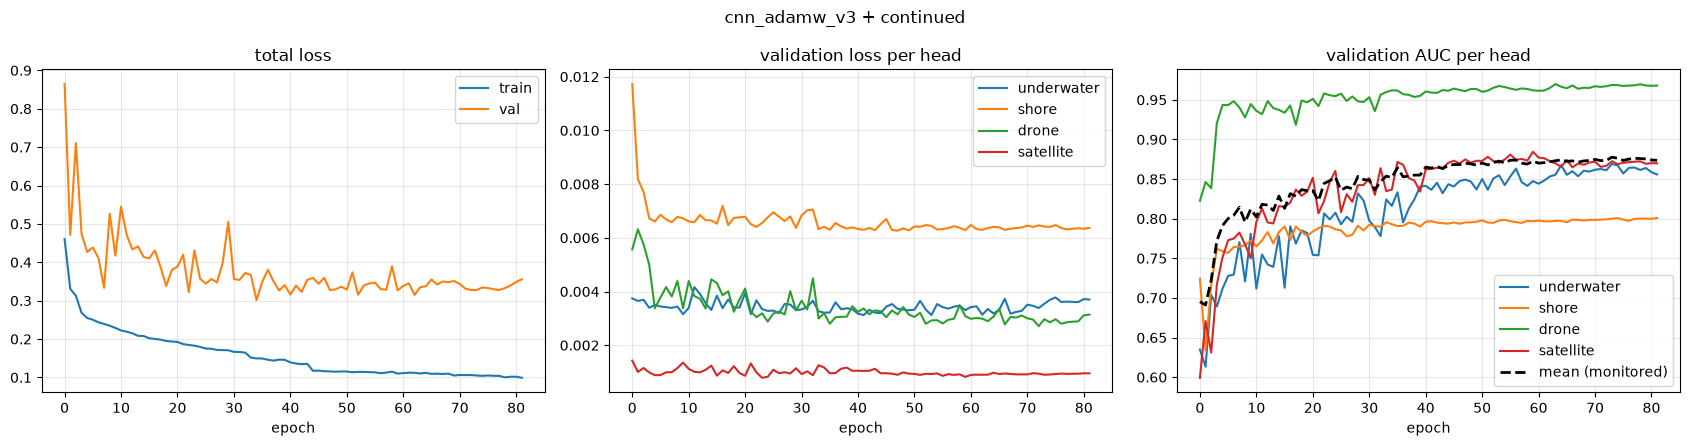

best epoch overall: 74 (continued from epoch 61)  |  mean trash-head val AUC 0.8776
underwater   val AUC 0.869   trash/no-trash AUC 0.792
shore        val AUC 0.800   trash/no-trash AUC 0.914
drone        val AUC 0.969   trash/no-trash AUC 0.976
satellite    val AUC 0.873   trash/no-trash AUC 0.877


In [14]:
plot_history(hist, title=f"{SOURCE_RUN} + continued")
best = int(np.nanargmax(hist["val_trash_auc"]))
print(f"best epoch overall: {best + 1} (continued from epoch {start + 1})  |  mean trash-head val AUC {hist['val_trash_auc'][best]:.4f}")
for h in HEADS:
    print(f"{h:11s}  val AUC {hist[f'val_{h}_auc'][best]:.3f}   trash/no-trash AUC {hist[f'val_{h}_trash_auc'][best]:.3f}")